# 01 · Data pipeline and multimodal MLP baselines

Loads GDSC2 drug-response data via PyTDC, featurizes drugs as 2,048-bit Morgan fingerprints (RDKit) and cell lines as 17,737-dim gene-expression vectors, then trains two PyTorch baselines (a simple MLP and a deeper MLP).

**Run this notebook first.** `02_vae_pretraining.ipynb` reuses the tensors built here (run it in the same kernel session).

In [ ]:
!pip install PyTDC

In [4]:
from tdc.multi_pred import DrugRes
import pandas
data = DrugRes(name = 'GDSC2')
split = data.get_split() #random split
print(split.keys())


Found local copy...
Loading...
Done!


dict_keys(['train', 'valid', 'test'])


In [5]:
train_df = split['train']
valid_df = split['valid']
test_df = split['test']

In [6]:
print(train_df.head())
print(train_df.columns)
print(train_df.shape)

        Drug_ID                                               Drug  \
0  Camptothecin  CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...   
1  Camptothecin  CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...   
2  Camptothecin  CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...   
3  Camptothecin  CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...   
4  Camptothecin  CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...   

  Cell Line_ID                                          Cell Line         Y  
0      HCC1954  [8.54820830373167, 2.5996072676336297, 10.3759... -0.251083  
1      HCC1143  [7.58193774904993, 2.81430257671695, 10.363326...  1.343315  
2      HCC1187  [9.013252540641961, 2.9520929896608, 9.3474286...  1.736985  
3      HCC1395  [7.4351511634642105, 2.8325700611437004, 10.34... -2.309078  
4      HCC1599  [8.334239608034789, 2.7477031637484997, 10.314... -3.106684  
Index(['Drug_ID', 'Drug', 'Cell Line_ID', 'Cell Line', 'Y'], dtype='object')
(64892, 5)


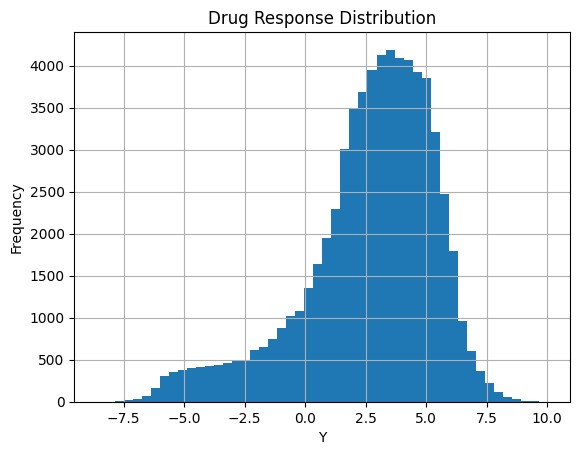

In [7]:
train_df['Y'].hist(bins=50)
import matplotlib.pyplot as plt
plt.title("Drug Response Distribution")
plt.xlabel("Y")
plt.ylabel("Frequency")
plt.show()

In [8]:
# 2. Look at one full row
train_df.iloc[0]

Drug_ID                                              Camptothecin
Drug            CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=...
Cell Line_ID                                              HCC1954
Cell Line       [8.54820830373167, 2.5996072676336297, 10.3759...
Y                                                       -0.251083
Name: 0, dtype: object

In [9]:
# 3. Missing values
train_df.isnull().sum()

Drug_ID         0
Drug            0
Cell Line_ID    0
Cell Line       0
Y               0
dtype: int64

In [10]:
#drug features
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

In [11]:
sample_smiles = train_df["Drug"].iloc[0]
print(sample_smiles)

CC[C@@]1(C2=C(COC1=O)C(=O)N3CC4=CC5=CC=CC=C5N=C4C3=C2)O


In [12]:
#convert smiles to mol
mol = Chem.MolFromSmiles(sample_smiles)
print(mol)

In [13]:
#create morgan fingerprint
fingerprint = AllChem.GetMorganFingerprintAsBitVect(
    mol,
    radius = 2,
    nBits=2048
)

In [14]:
#convert to numpy array
fp_array = np.array(fingerprint)
print(fp_array.shape)
print(fp_array[:20])

(2048,)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [15]:
def smiles_to_fp(smiles):
    #input=smiles string
    #output = 2048-dim numpy array
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return np.zeros(2048)
    fingerprint = AllChem.GetMorganFingerprintAsBitVect(
    mol,
    radius = 2,
    nBits=2048)
    fp_array = np.array(fingerprint)
    return fp_array

In [16]:
for i in range(5):#testing smiles_to_fp function
    smiles = train_df['Drug'].iloc[i]
    fp = smiles_to_fp(smiles)
    print(f"Drug {i}: {fp.shape}")

Drug 0: (2048,)
Drug 1: (2048,)
Drug 2: (2048,)
Drug 3: (2048,)
Drug 4: (2048,)


In [17]:
#test bad inputs
bad_smiles = "THIS_IS_NOT_A_MOLECULE"

fp = smiles_to_fp(bad_smiles)

print(fp.shape)
print(fp[:10])

(2048,)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


[18:11:59] SMILES Parse Error: syntax error while parsing: THIS_IS_NOT_A_MOLECULE
[18:11:59] SMILES Parse Error: Failed parsing SMILES 'THIS_IS_NOT_A_MOLECULE' for input: 'THIS_IS_NOT_A_MOLECULE'


In [18]:
#create drug feature matrix
#goal shape (num_samples, 2048)

'''hints
loop through train_df['Drug']
apply smiles_to_fp
store outputs in a list
convert to NumPy array
'''
X_features = []
for smiles in train_df['Drug']:
    fp = smiles_to_fp(smiles)
    X_features.append(fp)
X_features = np.array(X_features)
print(X_features.shape)

#each row is now a drug sample
#each column is now one molecular fingerprint feature
    
    

(64892, 2048)


In [19]:
cell_sample=train_df['Cell Line'].iloc[0]
print(type(cell_sample))
print(cell_sample)

<class 'numpy.ndarray'>
[ 8.5482083   2.59960727 10.37599067 ...  8.7813745   3.2325967
  7.8858243 ]


In [20]:
y_train = train_df['Y'].values
print(y_train.shape)

(64892,)


In [21]:
X_cell = np.array(train_df['Cell Line'].tolist())
print(X_cell.shape)
print(y_train.shape)
print(X_features.shape)

(64892, 17737)
(64892,)
(64892, 2048)


In [22]:
#import pytorch
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn


In [23]:
#convert NumPy array to tensors
X_drug_tensor = torch.tensor(X_features, dtype=torch.float32)
X_cell_tensor = torch.tensor(X_cell, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)
print(X_drug_tensor.shape)
print(X_cell_tensor.shape)
print(y_tensor.shape)

torch.Size([64892, 2048])
torch.Size([64892, 17737])
torch.Size([64892])


In [24]:
class DrugResponseDataset(Dataset):
    def __init__(self, X_drug, X_cell, y):
        self.X_drug = X_drug
        self.X_cell = X_cell
        self.y = y

    def __len__(self):
        return len(self.X_drug)
        #return total number of samples

    def __getitem__(self, idx):
        drug = self.X_drug[idx]
        cell = self.X_cell[idx]
        label = self.y[idx]
        return drug,cell,label
        #return drug features, cell features, label for one sample index

In [25]:
dataset = DrugResponseDataset(
    X_drug_tensor,
    X_cell_tensor,
    y_tensor
)
print(len(dataset))
drug, cell, label = dataset[0]

print(drug.shape)
print(cell.shape)
print(label)

64892
torch.Size([2048])
torch.Size([17737])
tensor(-0.2511)


In [26]:
from torch.utils.data import DataLoader
train_dataset = DrugResponseDataset( X_drug_tensor, X_cell_tensor, y_tensor)
train_loader = DataLoader(train_dataset, batch_size = 64, shuffle=True)

drug_batch, cell_batch, label_batch = next(iter(train_loader))
print(drug_batch.shape)
print(cell_batch.shape)
print(label_batch.shape)

torch.Size([64, 2048])
torch.Size([64, 17737])
torch.Size([64])


In [27]:
import torch.nn as nn
class DrugResponseModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.drug_encoder = nn.Sequential(
        nn.Linear(2048, 256),
        nn.ReLU(),
        nn.Dropout(0.2)
        )

        self.cell_encoder = nn.Sequential(
        nn.Linear(17737,256), #sample size, batch size
        nn.ReLU(),
        nn.Dropout(0.2)
        )

        self.regression_head = nn.Sequential(
        nn.Linear(512, 128),
        nn.ReLU(),
        nn.Linear(128, 1)
        )
    def forward(self, drug, cell):
        drug_emb = self.drug_encoder(drug)
        cell_emb = self.cell_encoder(cell)

        combined = torch.cat((drug_emb, cell_emb), dim=1)
        output = self.regression_head(combined)
        return  output.squeeze()



In [28]:
model=DrugResponseModel()
preds = model(drug_batch, cell_batch)
print(preds.shape)

torch.Size([64])


In [29]:
import torch.optim as optim
model = DrugResponseModel()
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

model.train()
total_loss = 0
for drug_batch, cell_batch, label_batch in train_loader:
    preds = model(drug_batch, cell_batch)
    loss = loss_fn(preds, label_batch)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_loss += loss.item()
avg_loss = total_loss / len(train_loader)
print("Training loss:", avg_loss)

Training loss: 6.147176378107165


In [30]:
X_valid_drug = np.array([smiles_to_fp(smiles) for smiles in valid_df['Drug']])
X_valid_cell = np.array(valid_df['Cell Line'].tolist())
y_valid = valid_df['Y'].values

In [31]:
X_valid_drug_tensor = torch.tensor(X_valid_drug, dtype=torch.float32)
X_valid_cell_tensor = torch.tensor(X_valid_cell, dtype=torch.float32)
y_valid_tensor = torch.tensor(y_valid, dtype=torch.float32)

In [32]:
valid_dataset = DrugResponseDataset(
    X_valid_drug_tensor,
    X_valid_cell_tensor,
    y_valid_tensor
)
valid_loader = DataLoader(valid_dataset, batch_size=64, shuffle=False)

model.eval()
valid_loss = 0
with torch.no_grad():
    for drug_batch, cell_batch, label_batch in valid_loader:
        preds = model(drug_batch, cell_batch)
        loss = loss_fn(preds, label_batch)
        valid_loss += loss.item()
avg_valid_loss = valid_loss / len(valid_loader)
print("validation loss:", avg_valid_loss)

validation loss: 2.346726822030955


In [33]:
num_epochs = 10
train_losses = []
valid_losses = []

for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0

    for drug_batch, cell_batch, label_batch in train_loader:
        preds = model(drug_batch, cell_batch)
        loss = loss_fn(preds, label_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    total_valid_loss=0
    with torch.no_grad():
        for drug_batch, cell_batch, label_batch in valid_loader:
            preds = model(drug_batch, cell_batch)
            loss = loss_fn(preds, label_batch)
            total_valid_loss += loss.item()

    avg_valid_loss = total_valid_loss / len(valid_loader)
    valid_losses.append(avg_valid_loss)

    print(f"Epoch {epoch+1}: Train Loss ={avg_train_loss:.4f}, Val Loss={avg_valid_loss:.4f}")

Epoch 1: Train Loss =2.0224, Val Loss=2.1373
Epoch 2: Train Loss =1.9498, Val Loss=2.2458
Epoch 3: Train Loss =1.8635, Val Loss=2.5015
Epoch 4: Train Loss =1.8084, Val Loss=1.7234
Epoch 5: Train Loss =1.7722, Val Loss=2.1081
Epoch 6: Train Loss =1.7271, Val Loss=1.9293
Epoch 7: Train Loss =1.7088, Val Loss=2.5004
Epoch 8: Train Loss =1.7707, Val Loss=2.5952
Epoch 9: Train Loss =1.7612, Val Loss=1.6882
Epoch 10: Train Loss =1.7244, Val Loss=2.1182


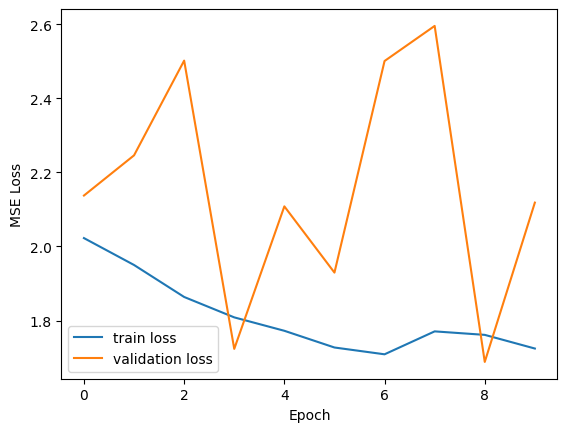

In [34]:
import matplotlib.pyplot as plt
plt.plot(train_losses, label="train loss")
plt.plot(valid_losses, label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for drug_batch, cell_batch, label_batch in valid_loader:
        preds = model(drug_batch, cell_batch)
        all_preds.extend(preds.numpy())
        all_labels.extend(label_batch.numpy())
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

mse = mean_squared_error(all_labels, all_preds)
rmse = np.sqrt(mse)
mae = mean_absolute_error(all_labels, all_preds)
r2 = r2_score(all_labels, all_preds)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

MSE: 2.1188158988952637
RMSE: 1.4556152990729603
MAE: 1.1070277690887451
R²: 0.7098135948181152


In [36]:
from scipy.stats import pearsonr, spearmanr
pearson_corr, _ = pearsonr(all_labels, all_preds)
spearman_corr, _ = spearmanr(all_labels, all_preds)
print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)

Pearson: 0.8751839
Spearman: 0.8408132809176451


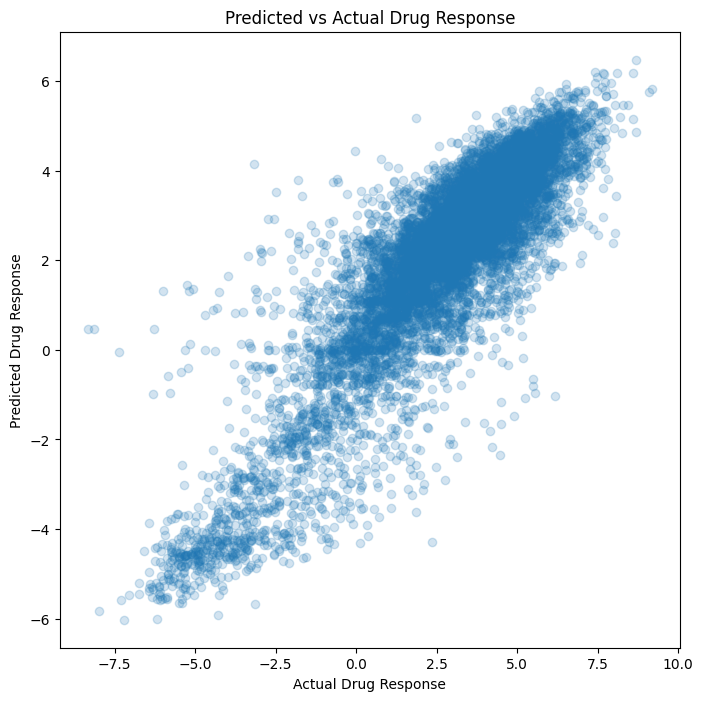

In [37]:
plt.figure(figsize=(8,8))
plt.scatter(all_labels, all_preds, alpha = 0.2)
plt.xlabel("Actual Drug Response")
plt.ylabel('Predicted Drug Response')
plt.title("Predicted vs Actual Drug Response")
plt.show()

In [38]:
#save baseline results
baseline_results = {
    "Model": "Baseline multimodal MLP",
    "Drug features": "Morgan fingerprint, 2048 bits",
    "Cell features": "Gene expression, 17,737 features",
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2": r2,
    "Pearson": pearson_corr,
    "Spearman": spearman_corr
}

baseline_results

{'Model': 'Baseline multimodal MLP',
 'Drug features': 'Morgan fingerprint, 2048 bits',
 'Cell features': 'Gene expression, 17,737 features',
 'MSE': 2.1188158988952637,
 'RMSE': 1.4556152990729603,
 'MAE': 1.1070277690887451,
 'R2': 0.7098135948181152,
 'Pearson': 0.8751839,
 'Spearman': 0.8408132809176451}

In [44]:
#improving architecture
class ImprovedDrugResponseModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.drug_encoder = nn.Sequential(
        nn.Linear(2048, 512),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(512,256),
        nn.ReLU()
        )

        self.cell_encoder = nn.Sequential(
        nn.Linear(17737, 2048),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(2048,512),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(512, 256),
        nn.ReLU()
        )

        self.regression_head = nn.Sequential(
        nn.Linear(512,256),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(256, 64),
        nn.ReLU(),
        nn.Linear(64,1)
        )

    def forward(self, drug, cell):
        drug_emb = self.drug_encoder(drug)
        cell_emb = self.cell_encoder(cell)
        combined = torch.cat((drug_emb, cell_emb), dim =1)
        output = self.regression_head(combined)
        return output.squeeze()

In [47]:
model = ImprovedDrugResponseModel()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.0001, weight_decay=1e-5)
num_epochs = 10

train_losses = []
valid_losses = []

for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0

    for drug_batch, cell_batch, label_batch in train_loader:
        preds = model(drug_batch, cell_batch)
        loss = loss_fn(preds, label_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    total_valid_loss = 0

    with torch.no_grad():
        for drug_batch, cell_batch, label_batch in valid_loader:
            preds = model(drug_batch, cell_batch)
            loss = loss_fn(preds, label_batch)
            total_valid_loss += loss.item()

    avg_valid_loss = total_valid_loss / len(valid_loader)
    valid_losses.append(avg_valid_loss)

    print(f"Epoch {epoch+1}: Train Loss={avg_train_loss:.4f}, Val Loss={avg_valid_loss:.4f}")

Epoch 1: Train Loss=2.7866, Val Loss=1.9429
Epoch 2: Train Loss=1.9561, Val Loss=1.8877
Epoch 3: Train Loss=1.8587, Val Loss=1.8082
Epoch 4: Train Loss=1.8431, Val Loss=1.8699
Epoch 5: Train Loss=1.9126, Val Loss=1.7157
Epoch 6: Train Loss=1.8463, Val Loss=1.9594
Epoch 7: Train Loss=1.8152, Val Loss=1.7484
Epoch 8: Train Loss=1.7959, Val Loss=1.9594
Epoch 9: Train Loss=1.7780, Val Loss=1.9147
Epoch 10: Train Loss=1.7613, Val Loss=1.8356


In [48]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for drug_batch, cell_batch, label_batch in valid_loader:
        preds = model(drug_batch, cell_batch)
        all_preds.extend(preds.numpy())
        all_labels.extend(label_batch.numpy())
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

mse = mean_squared_error(all_labels, all_preds)
rmse = np.sqrt(mse)
mae = mean_absolute_error(all_labels, all_preds)
r2 = r2_score(all_labels, all_preds)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

from scipy.stats import pearsonr, spearmanr
pearson_corr, _ = pearsonr(all_labels, all_preds)
spearman_corr, _ = spearmanr(all_labels, all_preds)
print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)

MSE: 1.8363078832626343
RMSE: 1.3551043809473255
MAE: 1.0180414915084839
R²: 0.7485049962997437
Pearson: 0.86850834
Spearman: 0.8289532067189989
